# Loan Eligibility Prediction — EDA & Model Training

This notebook documents the exploratory data analysis and model
training/comparison workflow used in the Flask application. It mirrors
the logic in `preprocessing.py` and `train_model.py` so the methodology
can be inspected and re-run step by step.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import preprocessing as prep

sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Load the dataset

In [2]:
df = prep.load_dataset("../dataset/loan_data.csv")
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,3+,Graduate,No,8032,0,127,360,1.0,Semiurban,Y
1,Female,No,0,Graduate,No,12366,0,161,360,0.0,Semiurban,Y
2,Male,Yes,2,Not Graduate,No,2506,2105,110,120,1.0,Urban,Y
3,Male,Yes,0,Graduate,No,2834,2589,124,360,1.0,Semiurban,Y
4,Male,No,0,Graduate,No,9050,0,90,180,1.0,Semiurban,Y


In [3]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    str    
 1   Married            614 non-null    str    
 2   Dependents         614 non-null    str    
 3   Education          614 non-null    str    
 4   Self_Employed      614 non-null    str    
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    int64  
 7   LoanAmount         614 non-null    int64  
 8   Loan_Amount_Term   614 non-null    int64  
 9   Credit_History     614 non-null    float64
 10  Property_Area      614 non-null    str    
 11  Loan_Status        614 non-null    str    
dtypes: float64(1), int64(4), str(7)
memory usage: 57.7 KB


Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

## 2. Data cleaning

In [4]:
clean_df = prep.clean_data(df)
clean_df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

## 3. Feature engineering

In [5]:
fe_df = prep.engineer_features(clean_df)
fe_df[["ApplicantIncome", "CoapplicantIncome", "TotalIncome", "LoanAmount", "DebtToIncomeRatio"]].head()

,ApplicantIncome,CoapplicantIncome,TotalIncome,LoanAmount,DebtToIncomeRatio
0,8032,0,8032,127,15.809785
1,12366,0,12366,161,13.018517
2,2506,2105,4611,110,23.850824
3,2834,2589,5423,124,22.861357
4,9050,0,9050,90,9.943653


## 4. Exploratory Data Analysis

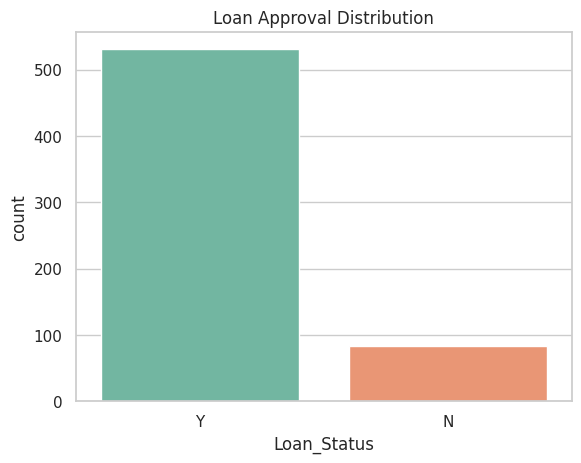

In [6]:
sns.countplot(data=fe_df, x="Loan_Status", hue="Loan_Status", palette="Set2", legend=False)
plt.title("Loan Approval Distribution")
plt.show()

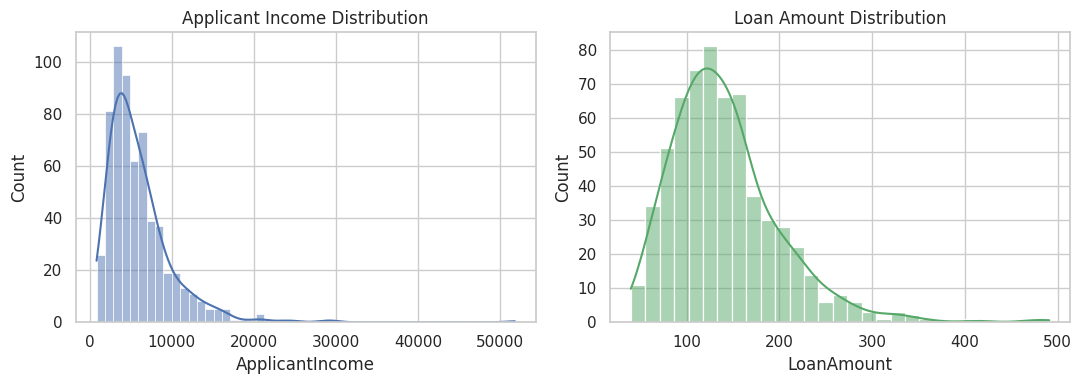

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(fe_df["ApplicantIncome"], kde=True, ax=axes[0], color="#4c72b0")
axes[0].set_title("Applicant Income Distribution")
sns.histplot(fe_df["LoanAmount"], kde=True, ax=axes[1], color="#55a868")
axes[1].set_title("Loan Amount Distribution")
plt.tight_layout()
plt.show()

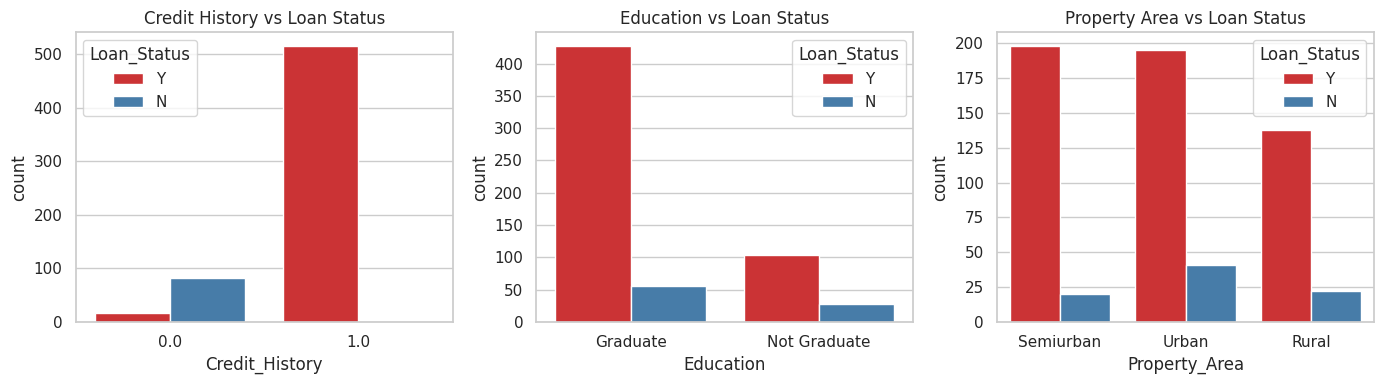

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.countplot(data=fe_df, x="Credit_History", hue="Loan_Status", ax=axes[0], palette="Set1")
axes[0].set_title("Credit History vs Loan Status")
sns.countplot(data=fe_df, x="Education", hue="Loan_Status", ax=axes[1], palette="Set1")
axes[1].set_title("Education vs Loan Status")
sns.countplot(data=fe_df, x="Property_Area", hue="Loan_Status", ax=axes[2], palette="Set1")
axes[2].set_title("Property Area vs Loan Status")
plt.tight_layout()
plt.show()

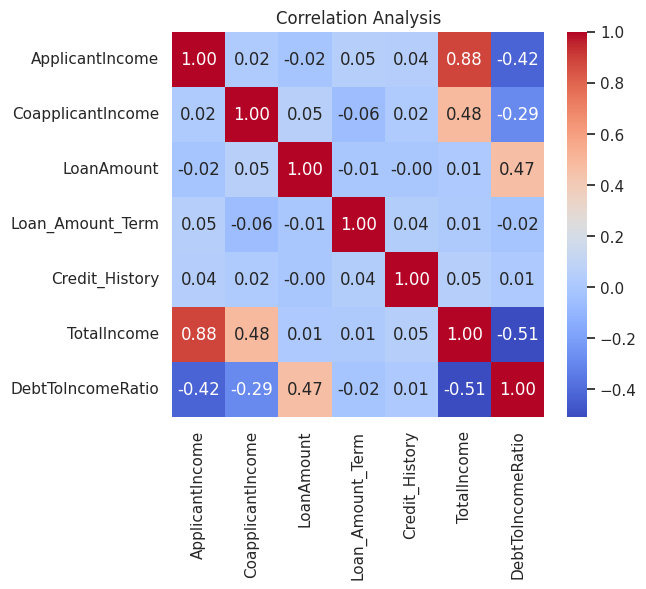

In [9]:
numeric_cols = prep.BASE_NUMERIC_FEATURES + ["TotalIncome", "DebtToIncomeRatio"]
plt.figure(figsize=(6, 5))
sns.heatmap(fe_df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Analysis")
plt.show()

## 5. Train/test split and model training

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

X, y = prep.prepare_features_and_target(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=6),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, max_depth=8),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([("preprocessor", prep.build_preprocessor()), ("classifier", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1_score": f1_score(y_test, y_pred, zero_division=0),
    }

pd.DataFrame(results).T

,accuracy,precision,recall,f1_score
Logistic Regression,0.99187,1.000000,0.990566,0.995261
Decision Tree,1.00000,1.000000,1.000000,1.000000
Random Forest,0.99187,0.990654,1.000000,0.995305


## 6. Best model selection

The model with the highest **F1-score** on the test set is selected — see
`train_model.py` for the full training script that also saves the chosen
model with `joblib` and generates the dashboard charts used by the Flask
app.